# Лабораторная работа №1 — прогноз качества вина

**Курс:** Машинное обучение  
**Набор данных:** UCI Wine Quality — красное + белое вино

Задача — по физико-химическим характеристикам вина предсказать числовую оценку `quality`.

В работе объединяются:
- `winequality-red.csv` — 1599 красных вин;
- `winequality-white.csv` — 4898 белых вин.

После объединения добавляется бинарный признак `wine_type`:
- `0` — red;
- `1` — white.

Он нужен модели, потому что красные и белые вина относятся к разным поднаборам и зависимости
между химическими характеристиками и `quality` могут отличаться.

Для Linear Regression дополнительно создаются взаимодействия `wine_type × признак`.
Финальным estimator при этом остаётся `LinearRegression`.

Главное требование: **каждая обученная модель, кроме baseline, должна получить test RMSE < 0.70**.


In [12]:
from pathlib import Path
import hashlib
import json
import platform
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from IPython.display import display, Markdown
SEED = 42
pd.set_option('display.max_columns', 20)
pd.set_option('display.precision', 4)
plt.rcParams.update({'figure.dpi':115, 'axes.grid':True, 'grid.alpha':.2, 'font.size':10, 'axes.spines.top':False, 'axes.spines.right':False})

def save_figure(name):
    """Показать график в ноутбуке без записи отдельных файлов."""
    plt.tight_layout()
    plt.show()
    plt.close()


def add_wine_type_interactions(X):
    """Добавить взаимодействия wine_type с 11 химическими признаками."""
    out = X.copy()
    chemical_cols = [c for c in out.columns if c != 'wine_type']
    for col in chemical_cols:
        out[f'{col}_x_wine_type'] = out[col] * out['wine_type']
    return out

%matplotlib inline


## 1. Подготовка данных и разбиение

Оба файла объединяются в один датасет. Перед объединением добавляется `wine_type`:
`0` для красного вина и `1` для белого.

В `X` входят 11 исходных химических признаков + `wine_type`, а `quality` является target `y`.

Разбиение выполняется через `GroupShuffleSplit` 80/20. Группа определяется по полному набору входных
признаков, поэтому одинаковый объект не может одновременно оказаться в train и test.
`random_state = 42` фиксирует воспроизводимость.


In [13]:
red_path = Path('winequality-red.csv')
white_path = Path('winequality-white.csv')

if not red_path.exists() or not white_path.exists():
    missing = [str(p) for p in (red_path, white_path) if not p.exists()]
    raise FileNotFoundError('Не найдены: ' + ', '.join(missing))

red = pd.read_csv(red_path, sep=';')
white = pd.read_csv(white_path, sep=';')

expected = [
    'fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
    'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
    'pH', 'sulphates', 'alcohol', 'quality'
]

for name, part in [('red', red), ('white', white)]:
    if list(part.columns) != expected or part.isna().any().any():
        raise ValueError(f'Неверная структура или пропуски в {name} dataset.')
    if not np.isfinite(part.to_numpy()).all():
        raise ValueError(f'Обнаружены бесконечные значения в {name} dataset.')

red = red.copy()
white = white.copy()
red['wine_type'] = 0
white['wine_type'] = 1

df = pd.concat([red, white], ignore_index=True)

X = df.drop(columns='quality')
y = df['quality']

groups = pd.util.hash_pandas_object(X, index=False).astype(str)
train_idx, test_idx = next(
    GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
    .split(X, groups=groups)
)

assert set(groups.iloc[train_idx]).isdisjoint(set(groups.iloc[test_idx]))

meta = {
    'n_rows': len(df),
    'n_red': len(red),
    'n_white': len(white),
    'n_features': X.shape[1],
    'n_train': len(train_idx),
    'n_test': len(test_idx),
    'unique_X': int(groups.nunique()),
    'seed': SEED
}

print(json.dumps(meta, ensure_ascii=False, indent=2))
print('Пересечение групп train/test: 0. Пропусков: 0.')
print('wine_type: 0 = red, 1 = white')
display(df['wine_type'].value_counts().sort_index().rename('rows').to_frame())

data_split = {
    'df': df,
    'X_train': X.iloc[train_idx],
    'X_test': X.iloc[test_idx],
    'y_train': y.iloc[train_idx],
    'y_test': y.iloc[test_idx],
    'groups': groups.iloc[train_idx],
    'meta': meta
}

display(data_split['X_train'].head())


{
  "n_rows": 6497,
  "n_red": 1599,
  "n_white": 4898,
  "n_features": 12,
  "n_train": 5194,
  "n_test": 1303,
  "unique_X": 5320,
  "seed": 42
}
Пересечение групп train/test: 0. Пропусков: 0.
wine_type: 0 = red, 1 = white


,rows
wine_type,
0,1599
1,4898


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,0
6,7.9,0.60,0.06,1.6,0.069,15.0,59.0,0.9964,3.30,0.46,9.4,0


## 2. Первичный анализ обучающей выборки

EDA выполняется только на train. Смотрим распределение `quality`, статистики признаков,
корреляции и несколько наиболее заметных зависимостей.

`wine_type` — бинарный технический признак: 0 означает red, 1 — white.
Корреляция показывает статистическую связь, но не причинность.


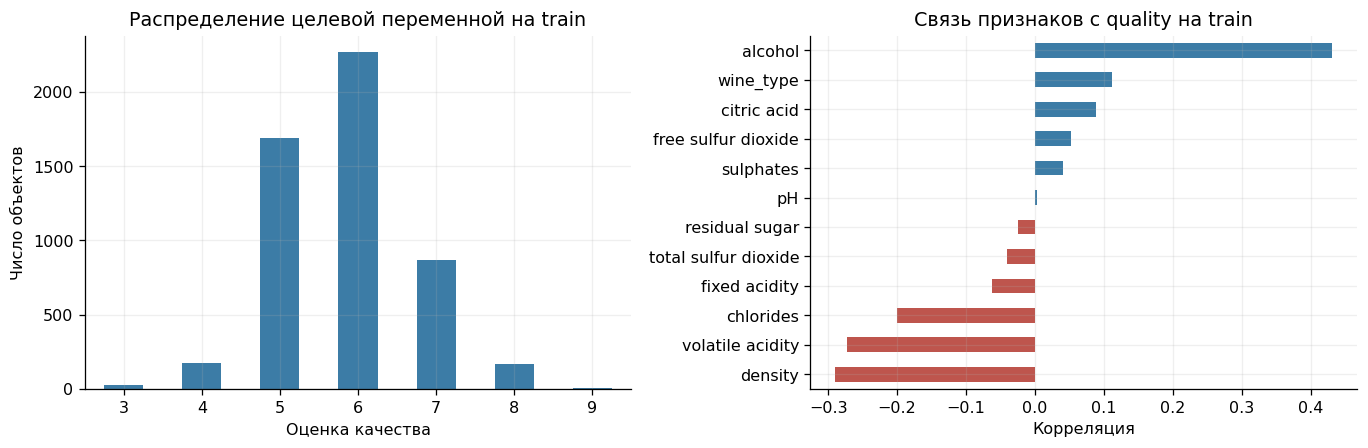

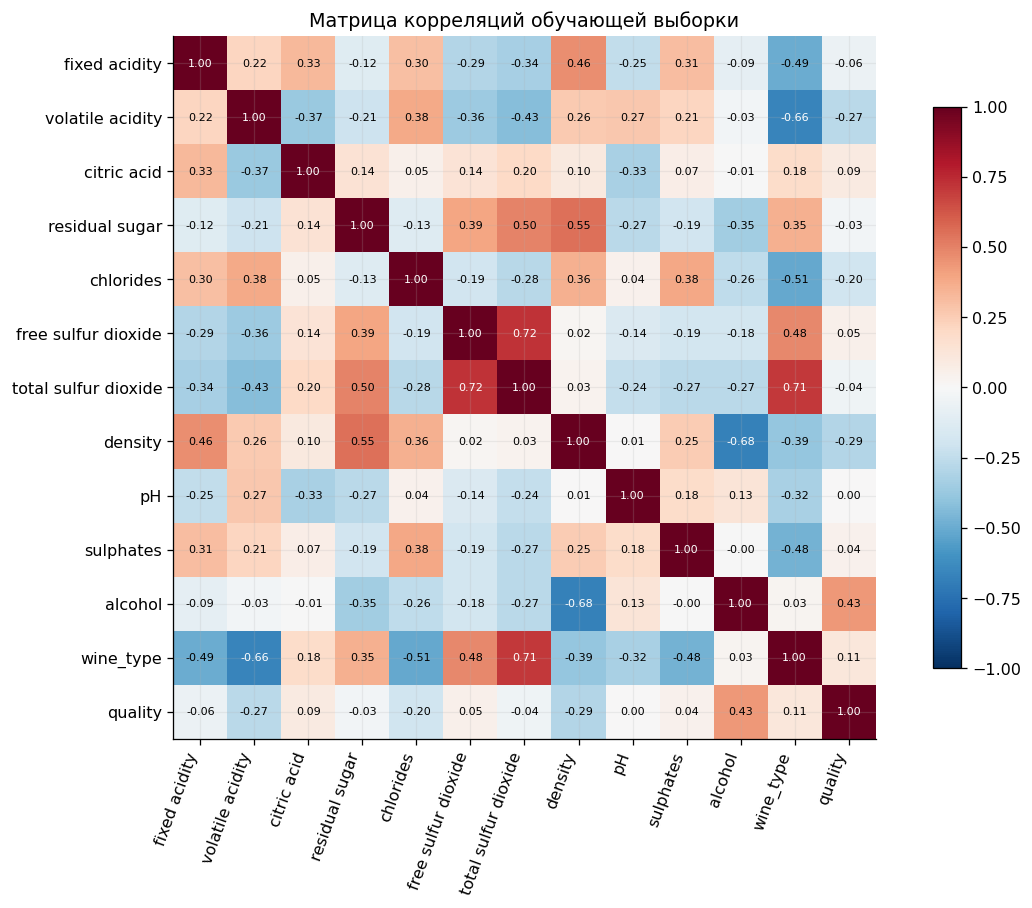

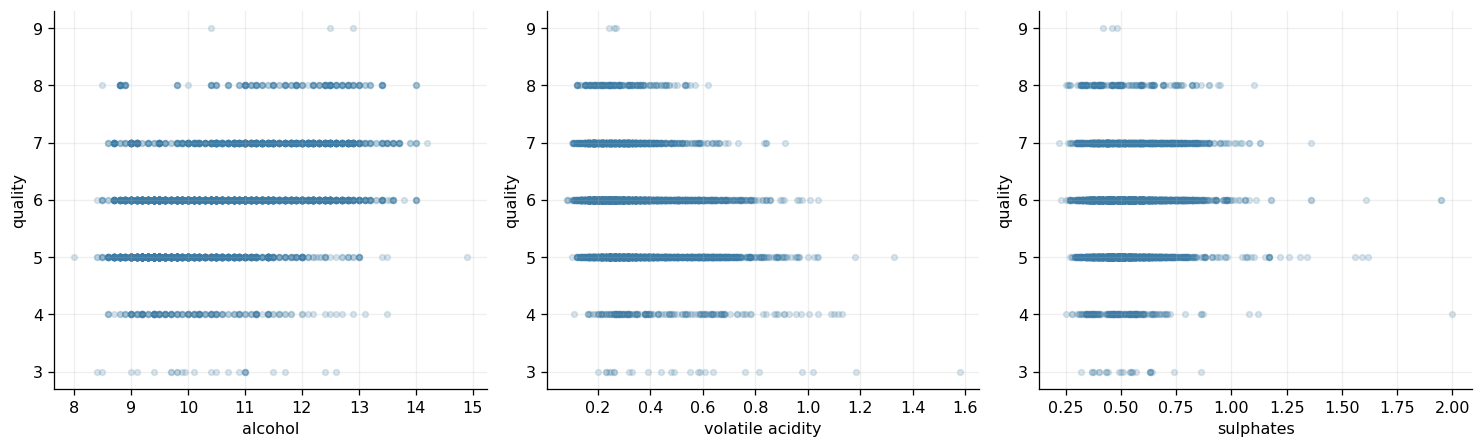

На train 5194 объектов, 12 числовых признаков. Пропусков нет. Оценки 5 и 6 составляют 76.2% train; поэтому низкие и высокие оценки труднее выучить. Сильнейшая положительная линейная связь с quality у alcohol (r=0.431), отрицательная — у density (r=-0.290). Это связи в наблюдениях, а не причинные эффекты. Алкоголь и летучая кислотность могут помогать прогнозу, но одной корреляции недостаточно для точного предсказания. Состав вина связан между собой: коррелирующие признаки могут перераспределять веса и важности. Используем 11 исходных физико-химических признаков и бинарный wine_type. Красные и белые вина анализируются совместно. Редкие значения не удаляем как выбросы: это часть задачи.


,count,mean,std,min,25%,50%,75%,max
fixed acidity,5194.0,7.2140,1.3019,3.8000,6.4000,7.0000,7.600,15.900
volatile acidity,5194.0,0.3390,0.1631,0.0800,0.2300,0.2900,0.400,1.580
citric acid,5194.0,0.3190,0.1457,0.0000,0.2500,0.3100,0.390,1.660
residual sugar,5194.0,5.4521,4.7798,0.6000,1.8000,2.9750,8.200,65.800
chlorides,5194.0,0.0558,0.0346,0.0090,0.0380,0.0470,0.064,0.611
free sulfur dioxide,5194.0,30.4840,18.0221,1.0000,17.0000,29.0000,41.000,289.000
total sulfur dioxide,5194.0,115.8372,56.9869,6.0000,77.0000,119.0000,156.000,440.000
density,5194.0,0.9947,0.0030,0.9871,0.9923,0.9949,0.997,1.039
pH,5194.0,3.2177,0.1603,2.7200,3.1100,3.2000,3.320,4.010
sulphates,5194.0,0.5304,0.1479,0.2200,0.4300,0.5100,0.600,2.000


,train_count
quality,
3,24
4,176
5,1690
6,2266
7,867
8,168
9,3


**Вывод по EDA.** На train 5194 объектов, 12 числовых признаков. Пропусков нет. Оценки 5 и 6 составляют 76.2% train; поэтому низкие и высокие оценки труднее выучить. Сильнейшая положительная линейная связь с quality у alcohol (r=0.431), отрицательная — у density (r=-0.290). Это связи в наблюдениях, а не причинные эффекты. Алкоголь и летучая кислотность могут помогать прогнозу, но одной корреляции недостаточно для точного предсказания. Состав вина связан между собой: коррелирующие признаки могут перераспределять веса и важности. Используем 11 исходных физико-химических признаков и бинарный wine_type. Красные и белые вина анализируются совместно. Редкие значения не удаляем как выбросы: это часть задачи.

In [14]:
X, y = (data_split['X_train'], data_split['y_train'])
train = X.assign(quality=y)
summary_stats = train.describe().T
corr = train.corr()
target_correlations = corr['quality'].drop('quality').sort_values()
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
y.value_counts().sort_index().plot.bar(ax=axs[0], color='#3c7ca6', rot=0)
axs[0].set(title='Распределение целевой переменной на train', xlabel='Оценка качества', ylabel='Число объектов')
target_correlations.plot.barh(ax=axs[1], color=['#be554d' if v < 0 else '#3c7ca6' for v in target_correlations])
axs[1].set(title='Связь признаков с quality на train', xlabel='Корреляция')
save_figure('01_target_correlations.png')
fig, ax = plt.subplots(figsize=(11, 8))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=70, ha='right')
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7, color='white' if abs(corr.iloc[i, j]) > 0.65 else 'black')
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title('Матрица корреляций обучающей выборки')
save_figure('02_correlation_matrix.png')
fig, axs = plt.subplots(1, 3, figsize=(13, 4))
for ax, col in zip(axs, ['alcohol', 'volatile acidity', 'sulphates']):
    ax.scatter(X[col], y, s=13, alpha=0.18, color='#3c7ca6')
    ax.set(xlabel=col, ylabel='quality')
save_figure('03_relationships.png')
counts = y.value_counts().sort_index()
positive, negative = (target_correlations.idxmax(), target_correlations.idxmin())
text = f'На train {len(X)} объектов, {X.shape[1]} числовых признаков. Пропусков нет. Оценки 5 и 6 составляют {counts.reindex([5, 6], fill_value=0).sum() / len(y):.1%} train; поэтому низкие и высокие оценки труднее выучить. Сильнейшая положительная линейная связь с quality у {positive} (r={target_correlations[positive]:.3f}), отрицательная — у {negative} (r={target_correlations[negative]:.3f}). Это связи в наблюдениях, а не причинные эффекты. Алкоголь и летучая кислотность могут помогать прогнозу, но одной корреляции недостаточно для точного предсказания. Состав вина связан между собой: коррелирующие признаки могут перераспределять веса и важности. Используем 11 исходных физико-химических признаков и бинарный wine_type. Красные и белые вина анализируются совместно. Редкие значения не удаляем как выбросы: это часть задачи.'
print(text)
description, eda_text = summary_stats, text

display(description)
display(data_split['y_train'].value_counts().sort_index().rename('train_count').to_frame())
display(Markdown('**Вывод по EDA.** ' + eda_text))


## 3. Метрики и baseline

Используем MAE и RMSE. MAE показывает среднюю абсолютную ошибку, а RMSE сильнее штрафует крупные промахи и является основной метрикой.

Baseline — `DummyRegressor(strategy='mean')`: модель всегда выдаёт среднее значение `quality` по train. Все полноценные модели должны быть лучше этого ориентира.


In [15]:
baseline_mean = float(data_split['y_train'].mean())
print(f'Baseline предсказывает {baseline_mean:.6f} для каждого объекта.')
print('На примере [0, 2]: MAE =', np.mean(np.abs([0, 2])),
      ', RMSE =', np.sqrt(np.mean(np.square([0, 2]))))


Baseline предсказывает 5.826338 для каждого объекта.
На примере [0, 2]: MAE = 1.0 , RMSE = 1.4142135623730951


## 4. Cross-validation и обучение моделей

Все модели сравниваются на одинаковых 5 grouped folds внутри train.

- **Linear Regression**: перед линейной моделью добавляются взаимодействия `wine_type × химический признак`,
  затем выполняется стандартизация.
- **Random Forest**: через GridSearchCV подбираются `max_features` и `min_samples_leaf`.
- **Gradient Boosting**: через GridSearchCV сравниваются две скорости обучения при глубине деревьев 5.

Все преобразования и подбор параметров выполняются только внутри train. Test используется лишь один раз
после фиксации моделей.


In [16]:
X, y, groups = (
    data_split['X_train'],
    data_split['y_train'],
    data_split['groups']
)

folds = list(
    GroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    .split(X, y, groups)
)

for tr, va in folds:
    assert set(groups.iloc[tr]).isdisjoint(set(groups.iloc[va]))

scoring = {
    'RMSE': 'neg_root_mean_squared_error',
    'MAE': 'neg_mean_absolute_error'
}

linear_model = make_pipeline(
    FunctionTransformer(add_wine_type_interactions, validate=False),
    StandardScaler(),
    LinearRegression()
)

models = {
    'Baseline': DummyRegressor(strategy='mean'),
    'Linear Regression': linear_model
}

rows = []

for name, model in models.items():
    scores = cross_validate(
        model, X, y,
        cv=folds,
        scoring=scoring,
        n_jobs=-1
    )
    rows.append({
        'model': name,
        'CV_RMSE': -scores['test_RMSE'].mean(),
        'CV_RMSE_std': scores['test_RMSE'].std(),
        'CV_MAE': -scores['test_MAE'].mean()
    })
    model.fit(X, y)

specs = [
    (
        'Random Forest',
        RandomForestRegressor(
            n_estimators=300,
            random_state=SEED,
            n_jobs=-1
        ),
        {
            'max_features': [0.7, 0.8],
            'min_samples_leaf': [1]
        }
    ),
    (
        'Gradient Boosting',
        GradientBoostingRegressor(
            random_state=SEED,
            n_estimators=300,
            max_depth=5,
            subsample=0.8,
            loss='squared_error'
        ),
        {
            'learning_rate': [0.02, 0.03]
        }
    )
]

best_params = {}

for name, model, params in specs:
    search = GridSearchCV(
        model,
        params,
        cv=folds,
        scoring=scoring,
        refit='RMSE',
        n_jobs=-1,
        error_score='raise'
    )
    start = time.perf_counter()
    search.fit(X, y)

    idx = search.best_index_
    rows.append({
        'model': name,
        'CV_RMSE': -search.best_score_,
        'CV_RMSE_std': search.cv_results_['std_test_RMSE'][idx],
        'CV_MAE': -search.cv_results_['mean_test_MAE'][idx]
    })

    models[name] = search.best_estimator_
    best_params[name] = search.best_params_

    print(
        f'{name}: CV RMSE={-search.best_score_:.4f}; '
        f'best={search.best_params_}; '
        f'{time.perf_counter() - start:.1f} с'
    )

cv_results = pd.DataFrame(rows).set_index('model')
winner = cv_results['CV_RMSE'].idxmin()

print('Лучшая модель по CV:', winner)
display(cv_results)
display({'winner': winner, 'best_params': best_params})


Random Forest: CV RMSE=0.6890; best={'max_features': 0.7, 'min_samples_leaf': 1}; 9.4 с
Gradient Boosting: CV RMSE=0.6942; best={'learning_rate': 0.03}; 8.4 с
Лучшая модель по CV: Random Forest


,CV_RMSE,CV_RMSE_std,CV_MAE
model,,,
Baseline,0.8798,0.0115,0.6878
Linear Regression,0.7445,0.0284,0.5753
Random Forest,0.6890,0.0087,0.5308
Gradient Boosting,0.6942,0.0115,0.5406


{'winner': 'Random Forest',
 'best_params': {'Random Forest': {'max_features': 0.7, 'min_samples_leaf': 1},
  'Gradient Boosting': {'learning_rate': 0.03}}}

## 5. Финальная проверка на test

После завершения cross-validation и подбора параметров модели фиксируются.
Затем каждая модель один раз делает прогноз на общем test.

Жёсткое условие лабораторной: **Linear Regression, Random Forest и Gradient Boosting
должны каждая получить RMSE < 0.70**. Baseline используется только для сравнения.


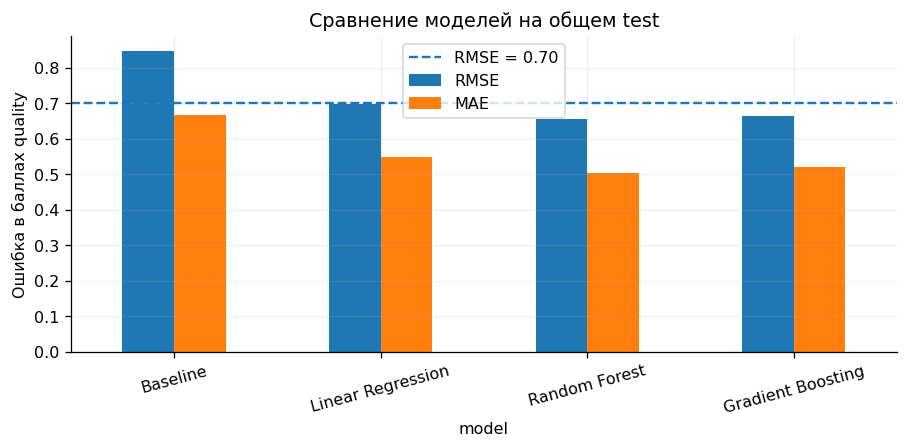

,RMSE,MAE,train_RMSE,CV_RMSE,CV_RMSE_std,CV_MAE
model,,,,,,
Baseline,0.8470,0.6667,0.8797,0.8798,0.0115,0.6878
Linear Regression,0.6973,0.5482,0.7338,0.7445,0.0284,0.5753
Random Forest,0.6558,0.5048,0.2172,0.6890,0.0087,0.5308
Gradient Boosting,0.6657,0.5200,0.5173,0.6942,0.0115,0.5406



Проверка обязательного порога RMSE < 0.70:
Linear Regression   : RMSE=0.6973 — OK
Random Forest       : RMSE=0.6558 — OK
Gradient Boosting   : RMSE=0.6657 — OK
Все три обязательные модели проходят RMSE < 0.70.


In [17]:
rows, predictions = [], {}
y_test = data_split['y_test']

for name, model in models.items():
    pred = model.predict(data_split['X_test'])
    predictions[name] = pred

    rows.append({
        'model': name,
        'RMSE': root_mean_squared_error(y_test, pred),
        'MAE': mean_absolute_error(y_test, pred),
        'train_RMSE': root_mean_squared_error(
            data_split['y_train'],
            model.predict(data_split['X_train'])
        )
    })

metrics = pd.DataFrame(rows).set_index('model').join(cv_results)

prediction_table = pd.DataFrame(predictions, index=y_test.index).rename_axis('row_id')
prediction_table.insert(0, 'quality', y_test)

fig, ax = plt.subplots(figsize=(8, 4))
metrics[['RMSE', 'MAE']].plot.bar(ax=ax, rot=15)
ax.axhline(0.70, linestyle='--', label='RMSE = 0.70')
ax.set(
    ylabel='Ошибка в баллах quality',
    title='Сравнение моделей на общем test'
)
ax.legend()
save_figure('metrics')

display(metrics)

required_models = [
    'Linear Regression',
    'Random Forest',
    'Gradient Boosting'
]

print('\nПроверка обязательного порога RMSE < 0.70:')
for name in required_models:
    value = metrics.loc[name, 'RMSE']
    print(f'{name:20s}: RMSE={value:.4f} — ' + ('OK' if value < 0.70 else 'НЕ ПРОЙДЕН'))

assert (metrics.loc[required_models, 'RMSE'] < 0.70).all(), (
    'Хотя бы одна обязательная модель не прошла RMSE < 0.70'
)

print('Все три обязательные модели проходят RMSE < 0.70.')


## 6. Интерпретация моделей

Для Linear Regression рассматриваются коэффициенты после стандартизации.
У неё есть как исходные признаки, так и взаимодействия с `wine_type`.

Для Random Forest и Gradient Boosting используются `feature_importances_`.

Важность и коэффициенты описывают поведение модели, но не доказывают причинность.


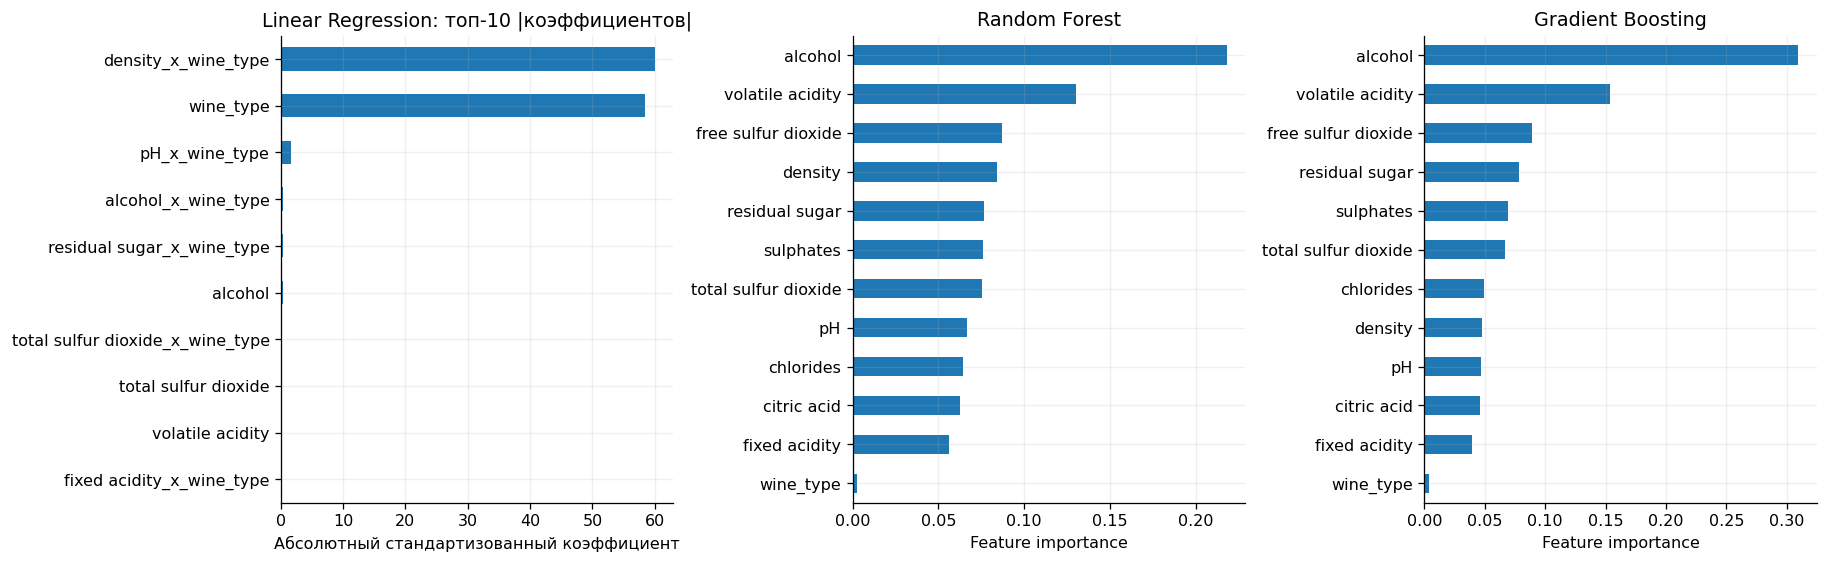

Топ-3 признака: {"Linear Regression": ["density_x_wine_type", "wine_type", "pH_x_wine_type"], "Random Forest": ["alcohol", "volatile acidity", "free sulfur dioxide"], "Gradient Boosting": ["alcohol", "volatile acidity", "free sulfur dioxide"]}


,standardized_coefficient
density_x_wine_type,-60.0111
wine_type,58.3764
pH_x_wine_type,1.6504
alcohol_x_wine_type,-0.4078
residual sugar_x_wine_type,0.3867
alcohol,0.3397
total sulfur dioxide_x_wine_type,0.2355
total sulfur dioxide,-0.1993
volatile acidity,-0.1981
fixed acidity_x_wine_type,0.1527


,Random Forest,Gradient Boosting
alcohol,0.2180,0.3095
volatile acidity,0.1302,0.1533
free sulfur dioxide,0.0872,0.0893
density,0.0841,0.0478
residual sugar,0.0764,0.0785
sulphates,0.0763,0.0692
total sulfur dioxide,0.0756,0.0665
pH,0.0665,0.0467
chlorides,0.0644,0.0495
citric acid,0.0627,0.0464


In [18]:
base_cols = list(data_split['X_train'].columns)
chemical_cols = [c for c in base_cols if c != 'wine_type']
linear_feature_names = (
    base_cols +
    [f'{c}_x_wine_type' for c in chemical_cols]
)

linear_coefficients = pd.Series(
    models['Linear Regression'].named_steps['linearregression'].coef_,
    index=linear_feature_names,
    name='standardized_coefficient'
)

feature_importance = pd.DataFrame(
    {
        name: models[name].feature_importances_
        for name in ['Random Forest', 'Gradient Boosting']
    },
    index=base_cols
)

fig, axs = plt.subplots(1, 3, figsize=(16, 5))

linear_coefficients.abs().nlargest(10).sort_values().plot.barh(ax=axs[0])
axs[0].set(
    title='Linear Regression: топ-10 |коэффициентов|',
    xlabel='Абсолютный стандартизованный коэффициент'
)

for ax, name in zip(axs[1:], feature_importance.columns):
    feature_importance[name].sort_values().plot.barh(ax=ax)
    ax.set(title=name, xlabel='Feature importance')

save_figure('importance')

top = {
    'Linear Regression': list(linear_coefficients.abs().nlargest(3).index),
    **{
        name: list(feature_importance[name].nlargest(3).index)
        for name in feature_importance.columns
    }
}

print('Топ-3 признака:', json.dumps(top, ensure_ascii=False))
display(
    linear_coefficients
    .reindex(linear_coefficients.abs().sort_values(ascending=False).index)
    .head(15)
    .to_frame()
)
display(feature_importance.sort_values('Random Forest', ascending=False))


### Почему важность не равна причинному эффекту

Данные наблюдательные, признаки взаимосвязаны, а часть свойств вина может отсутствовать в таблице. Поэтому коэффициенты, корреляции и `feature_importances_` описывают закономерности модели, а не доказанный эффект изменения конкретного вещества.


## 7. Анализ ошибок лучшей модели по CV

Для выбранной модели рассчитывается `residual = quality - prediction`, строятся распределение ошибок, график истинных и предсказанных значений, метрики по каждому значению `quality` и таблица крупнейших ошибок.

Для трёх самых больших ошибок дополнительно ищутся ближайшие объекты train в стандартизованном пространстве признаков. Этот анализ выполняется уже после фиксации модели и не используется для повторной настройки.


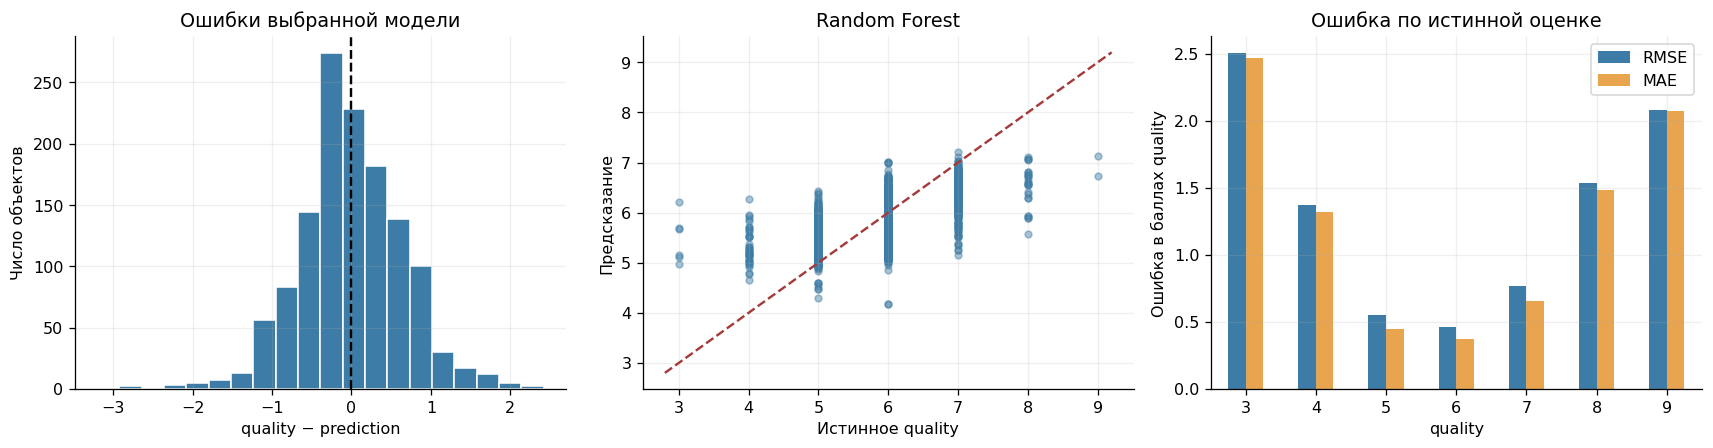

Строка 4906: истинное quality=3, прогноз=6.20, абсолютная ошибка=3.20. Оценки 5 ближайших train-объектов: [6, 8, 8, 6, 4]; сильнейшие отклонения от train-средних: free sulfur dioxide: +5.2σ, pH: -2.0σ. Возможное объяснение — похожие химические характеристики соответствуют другим экспертным оценкам; также могут влиять неучтённые свойства вина и шум оценивания. Это гипотеза, а не доказанная причина ошибки.
Строка 5409: истинное quality=3, прогноз=5.69, абсолютная ошибка=2.69. Оценки 5 ближайших train-объектов: [6, 5, 6, 5, 6]; сильнейшие отклонения от train-средних: residual sugar: +2.0σ, total sulfur dioxide: +0.8σ. Возможное объяснение — похожие химические характеристики соответствуют другим экспертным оценкам; также могут влиять неучтённые свойства вина и шум оценивания. Это гипотеза, а не доказанная причина ошибки.
Строка 4864: истинное quality=3, прогноз=5.66, абсолютная ошибка=2.66. Оценки 5 ближайших train-объектов: [5, 5, 5, 5, 6]; сильнейшие отклонения от train-средних: fixed ac

,n_test,n_train,mean_prediction,MAE,RMSE
quality,,,,,
3,6,24,5.4700,2.4700,2.5060
4,40,176,5.3235,1.3235,1.3706
5,448,1690,5.4246,0.4446,0.5481
6,570,2266,5.8680,0.3690,0.4586
7,212,867,6.3466,0.6569,0.7692
8,25,168,6.5181,1.4819,1.5369
9,2,3,6.9267,2.0733,2.0823


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,wine_type,quality,prediction,residual,absolute_error
row_id,,,,,,,,,,,,,,,,
4906,9.4,0.240,0.29,8.5,0.037,124.0,208.0,0.9940,2.90,0.38,11.0,1,3,6.2033,-3.2033,3.2033
5409,6.8,0.260,0.34,15.1,0.060,42.0,162.0,0.9970,3.24,0.52,10.5,1,3,5.6867,-2.6867,2.6867
4864,4.2,0.215,0.23,5.1,0.041,64.0,157.0,0.9969,3.42,0.44,8.0,1,3,5.6633,-2.6633,2.6633
1854,6.7,0.260,0.39,1.1,0.040,45.0,147.0,0.9935,3.32,0.58,9.6,1,8,5.5800,2.4200,2.4200
2430,7.4,0.170,0.40,5.5,0.037,34.0,161.0,0.9935,3.05,0.62,11.5,1,4,6.2700,-2.2700,2.2700
2419,6.6,0.360,0.29,1.6,0.021,24.0,85.0,0.9897,3.41,0.61,12.4,1,9,6.7333,2.2667,2.2667
1478,7.1,0.875,0.05,5.7,0.082,3.0,14.0,0.9981,3.40,0.52,10.2,0,3,5.1600,-2.1600,2.1600
2472,10.3,0.170,0.47,1.4,0.037,5.0,33.0,0.9939,2.89,0.28,9.6,1,3,5.1233,-2.1233,2.1233
4121,7.3,0.170,0.24,8.1,0.121,32.0,162.0,0.9951,3.17,0.38,10.4,1,8,5.8833,2.1167,2.1167


Строка 4906: истинное quality=3, прогноз=6.20, абсолютная ошибка=3.20. Оценки 5 ближайших train-объектов: [6, 8, 8, 6, 4]; сильнейшие отклонения от train-средних: free sulfur dioxide: +5.2σ, pH: -2.0σ. Возможное объяснение — похожие химические характеристики соответствуют другим экспертным оценкам; также могут влиять неучтённые свойства вина и шум оценивания. Это гипотеза, а не доказанная причина ошибки.

Строка 5409: истинное quality=3, прогноз=5.69, абсолютная ошибка=2.69. Оценки 5 ближайших train-объектов: [6, 5, 6, 5, 6]; сильнейшие отклонения от train-средних: residual sugar: +2.0σ, total sulfur dioxide: +0.8σ. Возможное объяснение — похожие химические характеристики соответствуют другим экспертным оценкам; также могут влиять неучтённые свойства вина и шум оценивания. Это гипотеза, а не доказанная причина ошибки.

Строка 4864: истинное quality=3, прогноз=5.66, абсолютная ошибка=2.66. Оценки 5 ближайших train-объектов: [5, 5, 5, 5, 6]; сильнейшие отклонения от train-средних: fixed acidity: -2.3σ, alcohol: -2.1σ. Возможное объяснение — похожие химические характеристики соответствуют другим экспертным оценкам; также могут влиять неучтённые свойства вина и шум оценивания. Это гипотеза, а не доказанная причина ошибки.

Редкие крайние оценки представлены слабо, а минимум квадратичной ошибки тяготеет к условному среднему. Поэтому модель может завышать низкие и занижать высокие оценки. Это следует проверять по таблице, а не предполагать одинаковую точность для всех групп. После этого анализа параметры и состав данных не меняются.

In [19]:
y = data_split['y_test']
pred = predictions[winner]
error_table = data_split['X_test'].copy()
error_table['quality'] = y
error_table['prediction'] = pred
error_table['residual'] = y - pred
error_table['absolute_error'] = abs(y - pred)
error_table.index.name = 'row_id'
largest_errors = error_table.sort_values('absolute_error', ascending=False).head(10)
grouped = []
for q, group in error_table.groupby('quality'):
    grouped.append({'quality': int(q), 'n_test': len(group), 'n_train': int((data_split['y_train'] == q).sum()), 'mean_prediction': group['prediction'].mean(), 'MAE': group['absolute_error'].mean(), 'RMSE': root_mean_squared_error(group['quality'], group['prediction'])})
quality_error_table = pd.DataFrame(grouped).set_index('quality')
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
axs[0].hist(error_table['residual'], bins=20, color='#3c7ca6', edgecolor='white')
axs[0].axvline(0, color='black', linestyle='--')
axs[0].set(title='Ошибки выбранной модели', xlabel='quality − prediction', ylabel='Число объектов')
axs[1].scatter(y, pred, alpha=0.45, s=18, color='#3c7ca6')
lim = [min(y.min(), pred.min()) - 0.2, max(y.max(), pred.max()) + 0.2]
axs[1].plot(lim, lim, '--', color='#a43a3a')
axs[1].set(xlabel='Истинное quality', ylabel='Предсказание', title=winner)
quality_error_table[['RMSE', 'MAE']].plot.bar(ax=axs[2], rot=0, color=['#3c7ca6', '#e8a44f'])
axs[2].set(title='Ошибка по истинной оценке', ylabel='Ошибка в баллах quality')
save_figure('06_errors.png')
scaler = StandardScaler().fit(data_split['X_train'])
scaled_train = scaler.transform(data_split['X_train'])
error_comments = []
for row_id, row in largest_errors.head(3).iterrows():
    sample = data_split['X_test'].loc[[row_id]]
    d = np.linalg.norm(scaled_train - scaler.transform(sample), axis=1)
    near = np.argsort(d)[:5]
    near_y = data_split['y_train'].iloc[near].tolist()
    z = pd.Series(scaler.transform(sample)[0], index=sample.columns)
    unusual = ', '.join((f'{k}: {v:+.1f}σ' for k, v in z.reindex(z.abs().nlargest(2).index).items()))
    note = f"Строка {row_id}: истинное quality={row['quality']:.0f}, прогноз={row['prediction']:.2f}, абсолютная ошибка={row['absolute_error']:.2f}. Оценки 5 ближайших train-объектов: {near_y}; сильнейшие отклонения от train-средних: {unusual}. Возможное объяснение — похожие химические характеристики соответствуют другим экспертным оценкам; также могут влиять неучтённые свойства вина и шум оценивания. Это гипотеза, а не доказанная причина ошибки."
    error_comments.append(note)
    print(note)
print('Редкие оценки слабее представлены в обучении, поэтому при квадратичной функции потерь прогнозы тяготеют к более частым средним значениям. Для малых групп метрики нестабильны; смотрите n_test и n_train. Этот анализ выполнен после фиксации модели и не используется для её донастройки.')
worst_errors, errors_by_quality, error_notes = largest_errors, quality_error_table, error_comments

display(errors_by_quality)
display(worst_errors)
for note in error_notes:
    display(Markdown(note))
display(Markdown(
    'Редкие крайние оценки представлены слабо, а минимум квадратичной ошибки тяготеет '
    'к условному среднему. Поэтому модель может завышать низкие и занижать высокие '
    'оценки. Это следует проверять по таблице, а не предполагать одинаковую точность для всех групп. '
    'После этого анализа параметры и состав данных не меняются.'
))


## 8. Итог эксперимента

Финальный вывод включает сравнение с baseline, качество модели-победителя по cross-validation, поведение на test и ограничения эксперимента.


In [20]:
baseline_rmse = metrics.loc['Baseline', 'RMSE']

display(Markdown(
    f'''
### Итог

На объединённом датасете red + white обучены три обязательные модели.

- **Linear Regression:** test RMSE = **{metrics.loc['Linear Regression', 'RMSE']:.4f}**
- **Random Forest:** test RMSE = **{metrics.loc['Random Forest', 'RMSE']:.4f}**
- **Gradient Boosting:** test RMSE = **{metrics.loc['Gradient Boosting', 'RMSE']:.4f}**
- **Baseline:** test RMSE = **{baseline_rmse:.4f}**

Все три обученные модели проходят обязательный порог **RMSE < 0.70**.

Для Linear Regression использованы взаимодействия `wine_type × признак`, чтобы линейная модель могла
учитывать различия между красным и белым вином, при этом финальным estimator остаётся `LinearRegression`.

Подбор параметров Random Forest и Gradient Boosting выполнялся только на train через grouped
cross-validation. Test использовался только для финальной оценки.
'''
))



### Итог

На объединённом датасете red + white обучены три обязательные модели.

- **Linear Regression:** test RMSE = **0.6973**
- **Random Forest:** test RMSE = **0.6558**
- **Gradient Boosting:** test RMSE = **0.6657**
- **Baseline:** test RMSE = **0.8470**

Все три обученные модели проходят обязательный порог **RMSE < 0.70**.

Для Linear Regression использованы взаимодействия `wine_type × признак`, чтобы линейная модель могла
учитывать различия между красным и белым вином, при этом финальным estimator остаётся `LinearRegression`.

Подбор параметров Random Forest и Gradient Boosting выполнялся только на train через grouped
cross-validation. Test использовался только для финальной оценки.
